In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [15]:
data = pd.read_csv('AirPassengers.csv')
data.head()

,Month,#Passengers
0,15-01-1949,112
1,15-02-1949,118
2,15-03-1949,132
3,15-04-1949,129
4,15-05-1949,121


In [16]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Month        144 non-null    str  
 1   #Passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 2.4 KB


In [17]:
data = data.set_index('Month')
data.head()

,#Passengers
Month,
15-01-1949,112
15-02-1949,118
15-03-1949,132
15-04-1949,129
15-05-1949,121


# Step-1 : Visualize the time series

check for trend, seasonality or random patterns

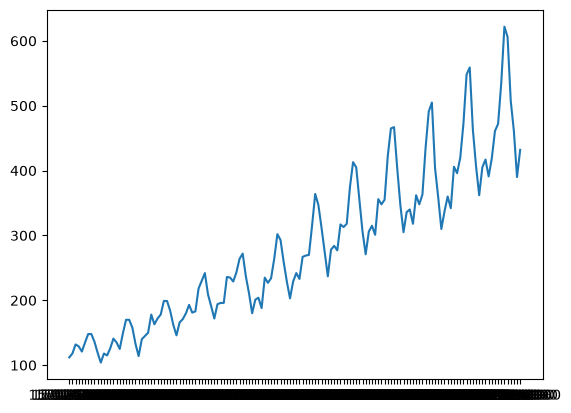

In [18]:
plt.plot(data)
plt.show()

## Step-2 : Check for stationarity

**Method-1 : Rolling Statistics**

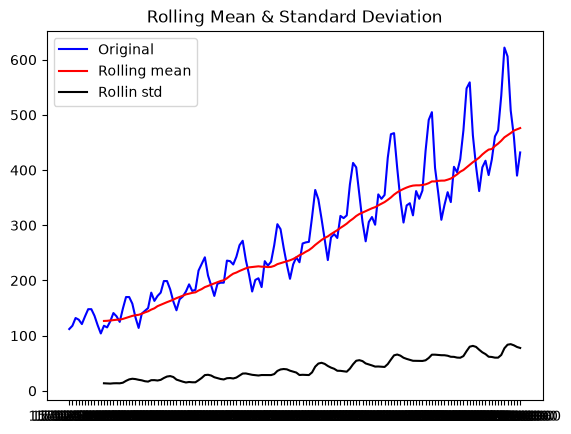

In [19]:
# Determing rolling statistics

rolmean = data.rolling(window=12).mean()
rolstd = data.rolling(window=12).std()

# Plot rolling statistics: 
orig = plt.plot(data, color = 'blue', label = 'Original')
mean = plt.plot(rolmean, color = 'red', label = 'Rolling mean')
std= plt.plot(rolstd, color = 'black', label = 'Rollin std')
plt.title('Rolling Mean & Standard Deviation')
plt.legend()
plt.show()

**Method 2: ADF Test**

In [20]:
## ADF Test - nul hypothesis - not-stationary - if p-value < 5% reject null hypothesis


from statsmodels.tsa.stattools import adfuller

adfuller_result = adfuller(data['#Passengers'].values)
adfuller_result

(0.8153688792060576,
 0.9918802434376411,
 13,
 130,
 {'1%': np.float64(-3.4816817173418295),
  '5%': np.float64(-2.8840418343195267),
  '10%': np.float64(-2.578770059171598)},
 np.float64(996.692930839019))

In [21]:
print('p-value : {}'.format(adfuller_result[1]))

p-value : 0.9918802434376411


p-value : 0.9918802434376411

The time series is not stationary

## Step-3: Stationarize the time series

**Differencing**

In [22]:
#Transformation

ts_log = np.log(data['#Passengers'])

# Get the difference between the movinf average and the actual number of passengers
ts_log_mv_diff = ts_log - ts_log.shift(2)

ts_log_mv_diff.head(15)

Month
15-01-1949         NaN
15-02-1949         NaN
15-03-1949    0.164303
15-04-1949    0.089128
15-05-1949   -0.087011
15-06-1949    0.045462
15-07-1949    0.201422
15-08-1949    0.091937
15-09-1949   -0.084557
15-10-1949   -0.218089
15-11-1949   -0.268264
15-12-1949   -0.008439
15-01-1950    0.100541
15-02-1950    0.065597
15-03-1950    0.203828
Name: #Passengers, dtype: float64

In [23]:
# Remove non values

ts_log_mv_diff.dropna(inplace=True)
ts_log_mv_diff.head()

Month
15-03-1949    0.164303
15-04-1949    0.089128
15-05-1949   -0.087011
15-06-1949    0.045462
15-07-1949    0.201422
Name: #Passengers, dtype: float64

**check for stationarity**

**Method-1: Rolling Statistics**

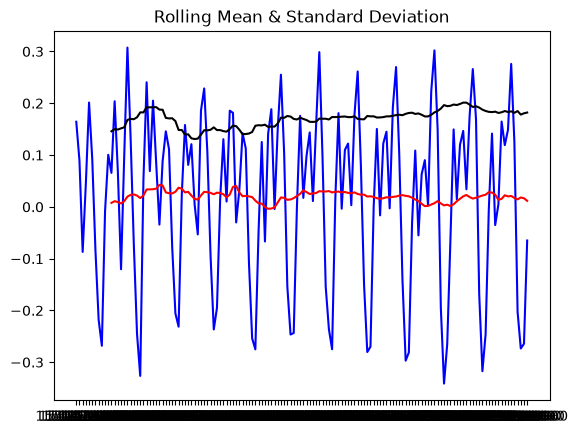

In [24]:
#Determing rolling statistics

rolmean = ts_log_mv_diff.rolling(window=12).mean()
rolstd = ts_log_mv_diff.rolling(window=12).std()

# Plot rolling statistics: 

orig = plt.plot(ts_log_mv_diff, color = 'blue', label = 'Original')
mean = plt.plot(rolmean, color='red', label = 'Rolling Mean')
std = plt.plot(rolstd, color ='black', label = 'Rolling Std')
plt.title('Rolling Mean & Standard Deviation')
plt.show()

**Method 2: ADF Test**

In [25]:
adfullr_result = adfuller(ts_log_mv_diff)
adfuller_result[1]

0.9918802434376411

## Step-4: Plot ACF/PACF and find p,d,q parameters

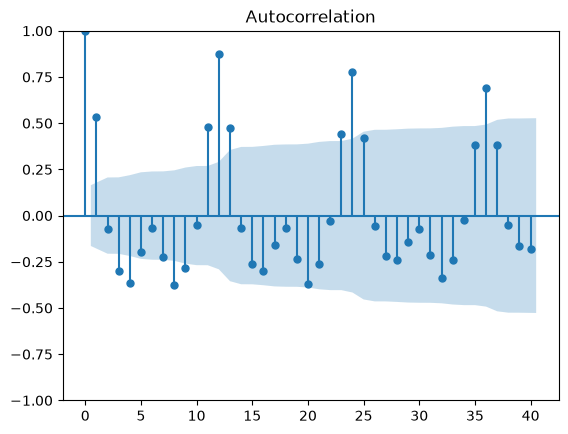

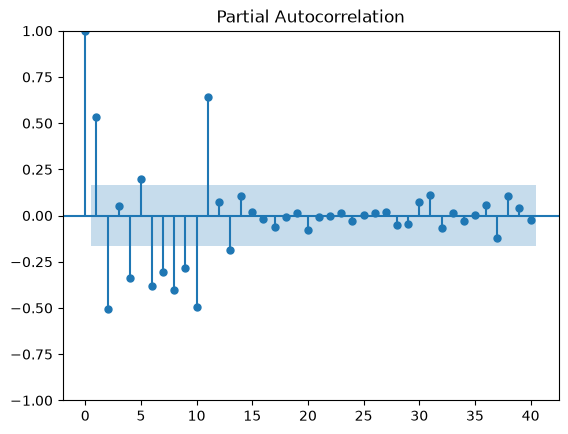

In [26]:
from statsmodels.tsa.stattools import acf, pacf
import statsmodels.api as sm
fig= sm.graphics.tsa.plot_acf(ts_log_mv_diff, lags= 40)
fig = sm.graphics.tsa.plot_pacf(ts_log_mv_diff, lags = 40)

## Build ARIMA Model

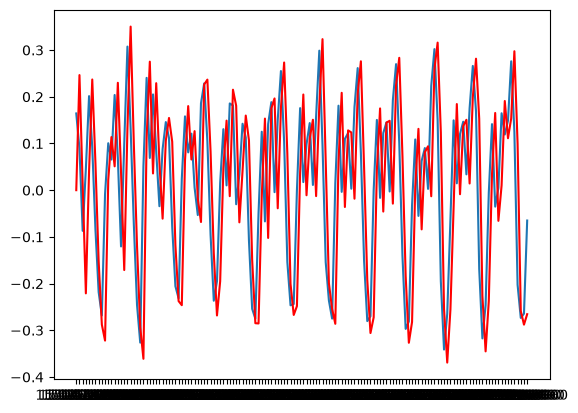

In [28]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(ts_log_mv_diff, order = (1,2,1))
results_ARIMA = model.fit()
plt.plot(ts_log_mv_diff)
plt.plot(results_ARIMA.fittedvalues, color='red')
plt.show()